# 01 - Estudo dos Dados

**Objetivo:** Entender a estrutura, schema e primeiras características do dataset de treino.

---

## Roteiro
1. Leitura do dataset
2. Shape e colunas
3. Tipos de dados
4. Valores nulos e duplicados
5. Estatísticas descritivas
6. Distribuição da classe alvo
7. Distribuição de `sex`
8. Comparação com `abalone_app.csv`
9. Resumo e próximos passos


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

DATA_DIR = '../'
TRAIN_FILE = "/home/antonio/Documentos/Machine Learning/mlclass/03_Validation/abalone_dataset.csv"
APP_FILE = "/home/antonio/Documentos/Machine Learning/mlclass/03_Validation/abalone_app.csv"
FEATURE_COLS = ['length', 'diameter', 'height', 'whole_weight',
            'shucked_weight', 'viscera_weight', 'shell_weight']
TARGET_COL = 'type'

print('Bibliotecas carregadas com sucesso!')


Bibliotecas carregadas com sucesso!


## 1. Leitura do Dataset

Carregando os arquivos de treino e aplicação.


In [9]:
df = pd.read_csv(TRAIN_FILE)
df_app = pd.read_csv(APP_FILE)

print(f'Treino: {df.shape[0]} linhas x {df.shape[1]} colunas')
print(f'Aplicação: {df_app.shape[0]} linhas x {df_app.shape[1]} colunas')
print('\n Primeiras linhas do treino:')
print(df.head())


Treino: 3132 linhas x 9 colunas
Aplicação: 1045 linhas x 8 colunas

 Primeiras linhas do treino:
  sex  length  diameter  height  whole_weight  shucked_weight  viscera_weight  \
0   M   0.535     0.420   0.150        0.6995          0.2575          0.1530   
1   I   0.510     0.380   0.115        0.5155          0.2150          0.1135   
2   I   0.185     0.130   0.045        0.0290          0.0120          0.0075   
3   M   0.550     0.450   0.170        0.8100          0.3170          0.1570   
4   I   0.535     0.415   0.150        0.5765          0.3595          0.1350   

   shell_weight  type  
0        0.2400     3  
1        0.1660     1  
2        0.0095     1  
3        0.2200     3  
4        0.2250     1  


## 2. Estrutura Básica

Verificando colunas, tipos e informações iniciais.


In [10]:
print('--- Colunas ---')
print(df.columns.tolist())

print('\n--- Tipos ---')
print(df.dtypes)

print('\n--- Info geral ---')
df.info()


--- Colunas ---
['sex', 'length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight', 'type']

--- Tipos ---
sex                   str
length            float64
diameter          float64
height            float64
whole_weight      float64
shucked_weight    float64
viscera_weight    float64
shell_weight      float64
type                int64
dtype: object

--- Info geral ---
<class 'pandas.DataFrame'>
RangeIndex: 3132 entries, 0 to 3131
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sex             3132 non-null   str    
 1   length          3132 non-null   float64
 2   diameter        3132 non-null   float64
 3   height          3132 non-null   float64
 4   whole_weight    3132 non-null   float64
 5   shucked_weight  3132 non-null   float64
 6   viscera_weight  3132 non-null   float64
 7   shell_weight    3132 non-null   float64
 8   type            3132 non-null   int

## 3. Qualidade dos Dados

Conferindo nulos e duplicados.


In [11]:
print('--- Valores nulos (treino) ---')
print(df.isnull().sum())

print('\n--- Valores nulos (aplicação) ---')
print(df_app.isnull().sum())

print('\n--- Linhas duplicadas ---')
print('Treino:', df.duplicated().sum())
print('Aplicação:', df_app.duplicated().sum())


--- Valores nulos (treino) ---
sex               0
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
type              0
dtype: int64

--- Valores nulos (aplicação) ---
sex               0
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
dtype: int64

--- Linhas duplicadas ---
Treino: 0
Aplicação: 0


## 4. Estatísticas Descritivas

Resumo numérico das variáveis contínuas.


In [12]:
print(df[FEATURE_COLS].describe().round(3))


         length  diameter    height  whole_weight  shucked_weight  \
count  3132.000  3132.000  3132.000      3132.000        3132.000   
mean      0.521     0.406     0.138         0.819           0.355   
std       0.121     0.100     0.039         0.490           0.221   
min       0.075     0.055     0.000         0.002           0.001   
25%       0.450     0.345     0.110         0.436           0.182   
50%       0.540     0.420     0.140         0.787           0.330   
75%       0.610     0.480     0.165         1.142           0.498   
max       0.815     0.650     0.515         2.826           1.488   

       viscera_weight  shell_weight  
count        3132.000      3132.000  
mean            0.178         0.236  
std             0.110         0.139  
min             0.000         0.002  
25%             0.091         0.128  
50%             0.168         0.225  
75%             0.250         0.324  
max             0.760         1.005  


## 5. Distribuição da Classe Alvo

O problema é multiclasse: classes 1, 2 e 3.


--- Distribuição da classe target ---
type
1    1078
2    1003
3    1051
Name: count, dtype: int64

Percentual:
type
1    34.42
2    32.02
3    33.56
Name: count, dtype: float64


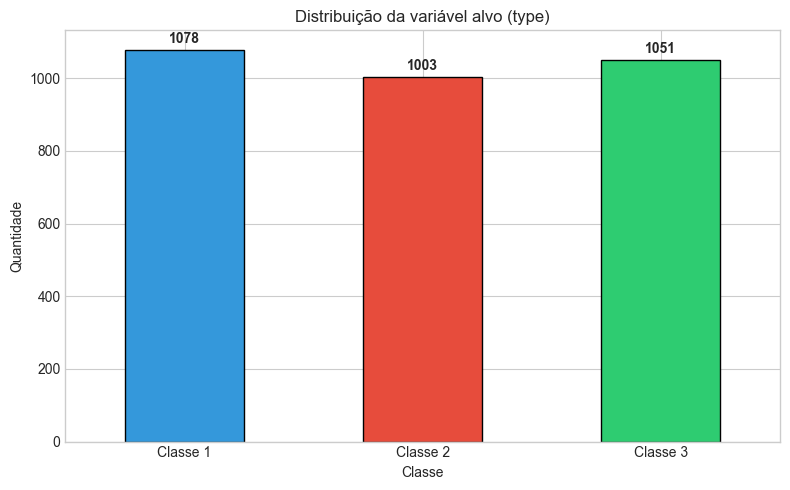

In [13]:
class_counts = df[TARGET_COL].value_counts().sort_index()
print('--- Distribuição da classe target ---')
print(class_counts)
print('\nPercentual:')
print((class_counts / len(df) * 100).round(2))

fig, ax = plt.subplots(figsize=(8, 5))
class_counts.plot(kind='bar', ax=ax, color=['#3498db', '#e74c3c', '#2ecc71'], edgecolor='black')
ax.set_title('Distribuição da variável alvo (type)')
ax.set_xlabel('Classe')
ax.set_ylabel('Quantidade')
ax.set_xticklabels(['Classe 1', 'Classe 2', 'Classe 3'], rotation=0)
for i, v in enumerate(class_counts):
    ax.text(i, v + 20, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Distribuição de `sex`

Observando a variável categórica de entrada.


--- Distribuição de sex ---
sex
M    1137
I    1042
F     953
Name: count, dtype: int64

Percentual:
sex
M    36.30
I    33.27
F    30.43
Name: count, dtype: float64


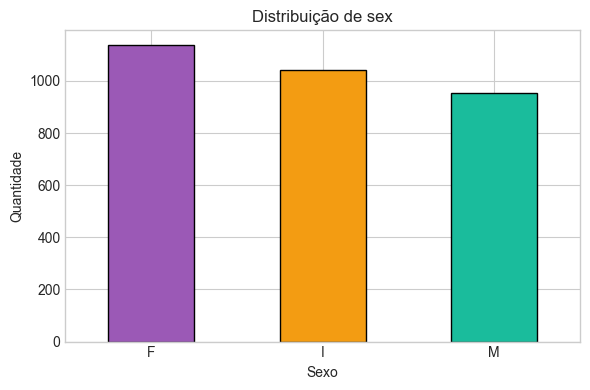

In [14]:
sex_counts = df['sex'].value_counts()
print('--- Distribuição de sex ---')
print(sex_counts)
print('\nPercentual:')
print((sex_counts / len(df) * 100).round(2))

fig, ax = plt.subplots(figsize=(6, 4))
sex_counts.plot(kind='bar', ax=ax, color=['#9b59b6', '#f39c12', '#1abc9c'], edgecolor='black')
ax.set_title('Distribuição de sex')
ax.set_xlabel('Sexo')
ax.set_ylabel('Quantidade')
ax.set_xticklabels(['F', 'I', 'M'], rotation=0)
plt.tight_layout()
plt.show()


## 7. Comparação Treino vs Aplicação

Checando se a base de aplicação parece vir da mesma população.


In [15]:
comparison = pd.DataFrame({
    'treino_mean': df[FEATURE_COLS].mean(),
    'app_mean': df_app[FEATURE_COLS].mean(),
    'treino_std': df[FEATURE_COLS].std(),
    'app_std': df_app[FEATURE_COLS].std(),
})

print('--- Comparação numérica ---')
print(comparison.round(3))

print('\n--- Distribuição de sex no treino ---')
print((df['sex'].value_counts(normalize=True) * 100).round(2))

print('\n--- Distribuição de sex na aplicação ---')
print((df_app['sex'].value_counts(normalize=True) * 100).round(2))


--- Comparação numérica ---
                treino_mean  app_mean  treino_std  app_std
length                0.521     0.532       0.121    0.118
diameter              0.406     0.414       0.100    0.098
height                0.138     0.143       0.039    0.049
whole_weight          0.819     0.859       0.490    0.492
shucked_weight        0.355     0.371       0.221    0.223
viscera_weight        0.178     0.187       0.110    0.110
shell_weight          0.236     0.248       0.139    0.139

--- Distribuição de sex no treino ---
sex
M    36.30
I    33.27
F    30.43
Name: proportion, dtype: float64

--- Distribuição de sex na aplicação ---
sex
M    37.42
F    33.88
I    28.71
Name: proportion, dtype: float64


## 8. Resumo e Próximos Passos

Preencha os insights depois de executar as células.

- [ ] Há nulos?
- [ ] Há duplicados?
- [ ] As classes estão balanceadas?
- [ ] As distribuições parecem plausíveis?
- [ ] Treino e aplicação parecem compatíveis?


In [16]:
print('=' * 60)
print('RESUMO DO ESTUDO DOS DADOS')
print('=' * 60)
print(f'Treino: {df.shape[0]} linhas e {df.shape[1]} colunas')
print(f'Aplicação: {df_app.shape[0]} linhas e {df_app.shape[1]} colunas')
print(f'Nulos no treino: {df.isnull().sum().sum()}')
print(f'Duplicados no treino: {df.duplicated().sum()}')
print(f'Classes: {df[TARGET_COL].value_counts().sort_index().to_dict()}')
print('\nPróximo passo: Notebook 02 - EDA detalhada')
print('=' * 60)


RESUMO DO ESTUDO DOS DADOS
Treino: 3132 linhas e 9 colunas
Aplicação: 1045 linhas e 8 colunas
Nulos no treino: 0
Duplicados no treino: 0
Classes: {1: 1078, 2: 1003, 3: 1051}

Próximo passo: Notebook 02 - EDA detalhada
